# 最小二乗法は物理・統計・機械学習で何をしているのか

## 概要

最小二乗法は、観測値とモデルの差の二乗和を小さくする方法である。物理では測定から定数を求め、統計では誤差の仮定に基づいて推定し、機械学習では予測モデルを学習する。本記事では共通の計算を導き、ばねの測定と多項式回帰をPythonで比較する。データはすべて人工的に生成する。

## 実行環境

仮想環境とカーネルは `wa-src(3.14.6)`、Pythonは `3.14.6` である。NumPyで計算し、Matplotlibで描画する。セルを上から順に実行する。小数の表示は有効数字3桁とし、計算値は丸めない。図はSVGで出力欄に埋め込み、実行時の作業ディレクトリの `101_nb_files` に保存する。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Latex, display
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
set_matplotlib_formats("svg")

assert platform.python_version() == "3.14.6"
assert sys.prefix != sys.base_prefix
print("実行環境: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.platform())
print("実行ファイル:", sys.executable)
pprint({"NumPy": np.__version__, "Matplotlib": matplotlib.__version__})

# 配列、軸目盛、式中の小数を同じ有効数字で表示する。
def sig3(value):
    return f"{float(value):#.3g}"


def tex3(value):
    parts = sig3(value).split("e")
    if len(parts) == 1:
        return parts[0]
    return parts[0] + rf"\times 10^{{{int(parts[1])}}}"


def show_formula(formula):
    # 重要な式は \( ... \) で囲み、LaTeX出力として表示する。
    display(Latex(r"\(\displaystyle " + formula + r"\)"))


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})
figure_dir = Path("101_nb_files")
figure_dir.mkdir(exist_ok=True)


def save_figure(fig, filename):
    """目盛を整え、SVGファイルとノートブックの両方に図を残す。"""
    for ax in fig.axes:
        if ax.get_xscale() == "log":
            ax.xaxis.set_major_locator(LogLocator(base=10, numticks=5))
        if ax.get_yscale() == "log":
            ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda value, pos: sig3(value)))
            axis.set_minor_formatter(NullFormatter())
        ax.grid(True, alpha=0.250)
    fig.tight_layout()
    fig.savefig(figure_dir / filename, format="svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: 3.14.6
OS: macOS-26.5.2-arm64-arm-64bit-Mach-O
実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
{'Matplotlib': '3.11.2', 'NumPy': '2.5.4'}


## 1. 共通する計算

観測を$\mathbf{y}$、係数を$\mathbf{b}$、説明変数を並べた行列を$\mathbf{X}$とする。残差$\mathbf{r}=\mathbf{y}-\mathbf{X}\mathbf{b}$の二乗和を最小化する。

$$
\begin{aligned}
S(\mathbf{b})
&=(\mathbf{y}-\mathbf{X}\mathbf{b})^{\mathsf T}(\mathbf{y}-\mathbf{X}\mathbf{b})\\
&=\mathbf{y}^{\mathsf T}\mathbf{y}-2\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{y}
+\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{b},\\
\nabla_{\mathbf{b}}S
&=-2\mathbf{X}^{\mathsf T}\mathbf{y}+2\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{b}=\mathbf{0},\\
\mathbf{X}^{\mathsf T}\mathbf{X}\hat{\mathbf{b}}&=\mathbf{X}^{\mathsf T}\mathbf{y}.
\end{aligned}
$$

$\mathbf{X}$の列が一次独立なら、$\mathbf{X}^{\mathsf T}\mathbf{X}$は正定値であり、解は一意に定まる。

In [2]:
show_formula(
    r"\hat{\mathbf{b}}=(\mathbf{X}^{\mathsf T}\mathbf{X})^{-1}"
    r"\mathbf{X}^{\mathsf T}\mathbf{y}"
)

<IPython.core.display.Latex object>

さらに$\mathbf{X}^{\mathsf T}\hat{\mathbf{r}}=\mathbf{X}^{\mathsf T}\mathbf{y}-\mathbf{X}^{\mathsf T}\mathbf{X}\hat{\mathbf{b}}=\mathbf{0}$である。予測は$\mathbf{y}$を$\mathbf{X}$の列空間へ直交射影したものになる。計算では逆行列を作らず、`np.linalg.lstsq`を使う。この関数は階数が不足する場合にも最小ノルムの解を返す。[NumPyの仕様](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)

## 2. 物理：測定からばね定数を求める

ばねを伸ばす外力を$F_i=c+kx_i+\varepsilon_i$とする。$x_i$は伸び、$k$はばね定数、$c$は力の測定のゼロ点ずれである。伸びの誤差は無視し、フックの法則が成り立つ範囲を扱う。$\mathbf{X}$の第$i$行は$(1,x_i)$、$\mathbf{b}=(c,k)^{\mathsf T}$となる。

$$
\begin{aligned}
S(c,k)&=\sum_i(F_i-c-kx_i)^2,\\
\frac{\partial S}{\partial c}&=-2\sum_i(F_i-c-kx_i)=0\\
&\Rightarrow\hat c=\bar F-\hat k\bar x,\\
\frac{\partial S}{\partial k}&=-2\sum_i x_i(F_i-c-kx_i)=0\\
&\Rightarrow\sum_i x_iF_i=(\bar F-\hat k\bar x)\sum_i x_i+\hat k\sum_i x_i^2\\
&=n\bar x\bar F+\hat k(\sum_i x_i^2-n\bar x^2),\\
\hat k&=\frac{\sum_i x_iF_i-n\bar x\bar F}{\sum_i x_i^2-n\bar x^2}.
\end{aligned}
$$

棒線は標本平均を表す。伸びがすべて同じなら分母はゼロとなり、$c$と$k$を分けて推定できない。

{'真値 [c, k]': array([0.100, 20.0]), '通常の最小二乗 [c, k]': array([0.123, 19.4])}


<IPython.core.display.Latex object>

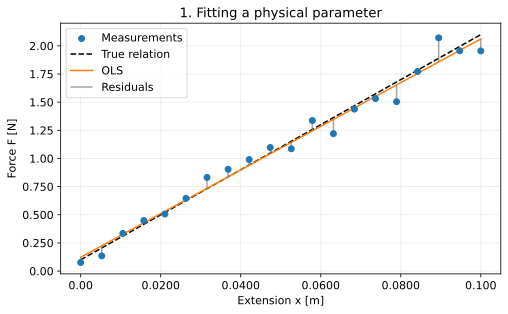

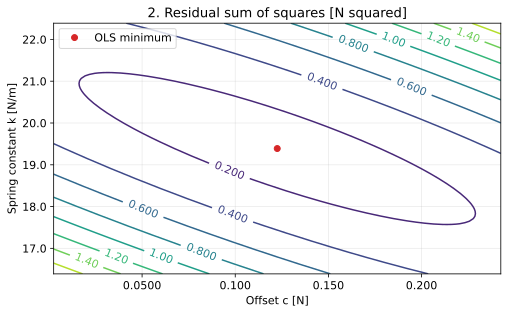

In [3]:
# 伸びは正確に制御し、力の測定だけに独立な正規誤差を加える。
rng_physics = np.random.default_rng(101)
x = np.linspace(0, 0.100, 20)
sigma = 0.0300 + 0.900 * x  # 各測定の既知の標準偏差 [N]
X = np.column_stack((np.ones(x.size), x))
b_true = np.array([0.100, 20.0])  # c [N], k [N/m]
force = X @ b_true + rng_physics.normal(0, sigma)
b_ols = np.linalg.lstsq(X, force, rcond=None)[0]
residual_ols = force - X @ b_ols

# 手計算の式と行列による解が一致することも確認する。
k_manual = ((x - x.mean()) @ (force - force.mean())) / np.sum((x - x.mean()) ** 2)
c_manual = force.mean() - k_manual * x.mean()
assert np.allclose(b_ols, [c_manual, k_manual])
assert np.allclose(X.T @ residual_ols, 0, atol=1.00e-12)
pprint({"真値 [c, k]": b_true, "通常の最小二乗 [c, k]": b_ols})
show_formula(rf"\hat F(x)={tex3(b_ols[0])}+{tex3(b_ols[1])}x")

fig, ax = plt.subplots(figsize=(7.20, 4.50))
ax.scatter(x, force, color="tab:blue", label="Measurements", zorder=3)
ax.plot(x, X @ b_true, "--", color="black", label="True relation")
ax.plot(x, X @ b_ols, color="tab:orange", label="OLS")
ax.vlines(x, X @ b_ols, force, color="tab:gray", alpha=0.700, label="Residuals")
ax.set(xlabel="Extension x [m]", ylabel="Force F [N]", title="1. Fitting a physical parameter")
ax.legend()
save_figure(fig, "01_spring_ols.svg")

# 切片と傾きを変えたときの二乗和を等高線にする。
c_grid = np.linspace(b_ols[0] - 0.120, b_ols[0] + 0.120, 101)
k_grid = np.linspace(b_ols[1] - 3, b_ols[1] + 3, 101)
C, K = np.meshgrid(c_grid, k_grid)
loss_grid = np.sum((force[:, None, None] - C - x[:, None, None] * K) ** 2, axis=0)
fig, ax = plt.subplots(figsize=(7.20, 4.50))
contours = ax.contour(C, K, loss_grid, levels=9, cmap="viridis")
ax.clabel(contours, fmt=lambda value: sig3(value))
ax.plot(*b_ols, "o", color="tab:red", label="OLS minimum")
ax.set(xlabel="Offset c [N]", ylabel="Spring constant k [N/m]", title="2. Residual sum of squares [N squared]")
ax.legend()
save_figure(fig, "02_loss_contours.svg")

図1の縦線が残差であり、その長さの二乗を足している。図2の楕円の傾きは、切片と傾きの変化が互いに補えることを示す。

測定ごとの標準偏差$\sigma_i$が既知なら、精度の違いを重みに反映できる。[重み付き最小二乗法](https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd432.htm)では

$$
S_w=\sum_i\left(\frac{F_i-c-kx_i}{\sigma_i}\right)^2
=\|\widetilde{\mathbf{y}}-\widetilde{\mathbf{X}}\mathbf{b}\|_2^2,
\quad \widetilde y_i=F_i/\sigma_i,\quad \widetilde X_{ij}=X_{ij}/\sigma_i
$$

を最小化する。重みは$1/\sigma_i^2$である。以下の誤差棒は$\pm\sigma_i$を表す。今回の重み付き推定は真値に近いが、毎回そうなる保証はない。

{'重み付き [c, k]': array([0.0934, 20.1]), '重み付き二乗和': '22.7'}


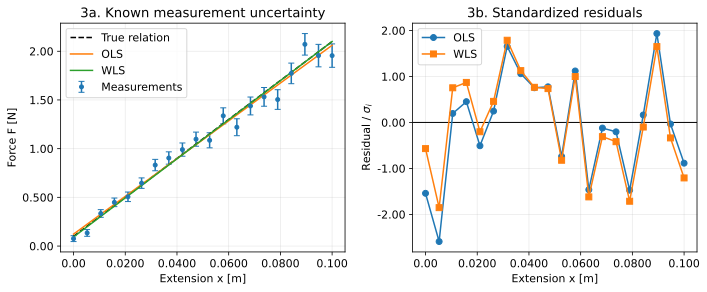

In [4]:
# 行ごとに標準偏差で割り、同じ最小二乗ソルバーへ渡す。
X_white = X / sigma[:, None]
force_white = force / sigma
b_wls = np.linalg.lstsq(X_white, force_white, rcond=None)[0]
residual_wls = force - X @ b_wls
assert np.allclose(X_white.T @ (residual_wls / sigma), 0, atol=1.00e-10)
pprint({"重み付き [c, k]": b_wls, "重み付き二乗和": sig3(np.sum((residual_wls / sigma) ** 2))})

fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.20))
axes[0].errorbar(x, force, yerr=sigma, fmt="o", markersize=4, capsize=3, label="Measurements")
axes[0].plot(x, X @ b_true, "--", color="black", label="True relation")
axes[0].plot(x, X @ b_ols, label="OLS")
axes[0].plot(x, X @ b_wls, label="WLS")
axes[0].set(xlabel="Extension x [m]", ylabel="Force F [N]", title="3a. Known measurement uncertainty")
axes[0].legend()
axes[1].axhline(0, color="black", linewidth=1)
axes[1].plot(x, residual_ols / sigma, "o-", label="OLS")
axes[1].plot(x, residual_wls / sigma, "s-", label="WLS")
axes[1].set(xlabel="Extension x [m]", ylabel=r"Residual / $\sigma_i$", title="3b. Standardized residuals")
axes[1].legend()
save_figure(fig, "03_weighted_fit_residuals.svg")

私は、係数だけでなく残差も並べる方が、モデルのずれを確認しやすいと感じる。二乗するため大きな外れ値の影響は強い。重みを付けても、法則の適用範囲や系統誤差の問題は解消しない。

## 3. 統計：正規誤差の最尤推定

誤差が独立で$\varepsilon_i\sim\mathcal N(0,\sigma_i^2)$に従い、$\sigma_i$が既知と仮定する。密度の積が尤度であり、対数を取ると積は和になる。

$$
\begin{aligned}
L(\mathbf{b})&=\prod_i\frac{1}{\sqrt{2\pi\sigma_i^2}}
\exp\left[-\frac{(F_i-c-kx_i)^2}{2\sigma_i^2}\right],\\
\log L(\mathbf{b})&=-\frac12\sum_i\log(2\pi\sigma_i^2)
-\frac12\sum_i\frac{(F_i-c-kx_i)^2}{\sigma_i^2},\\
-\log L(\mathbf{b})&=C+\frac12 S_w(\mathbf{b}).
\end{aligned}
$$

$C$は係数によらない定数である。尤度の最大化は重み付き二乗和の最小化と一致する。すべての$\sigma_i$が同じなら通常の最小二乗法になる。ただし、最小二乗という計算自体に正規分布の仮定は不要である。

図4左は$c$を推定値に固定した断面で、最小値からの増分を比べる。右は同じ測定を2000回生成し直した$\hat k$の分布である。一本の当てはめだけでは見えない推定のばらつきを確認できる。

{'kの平均 [N/m]': '20.0', 'kの標準偏差 [N/m]': '0.487'}


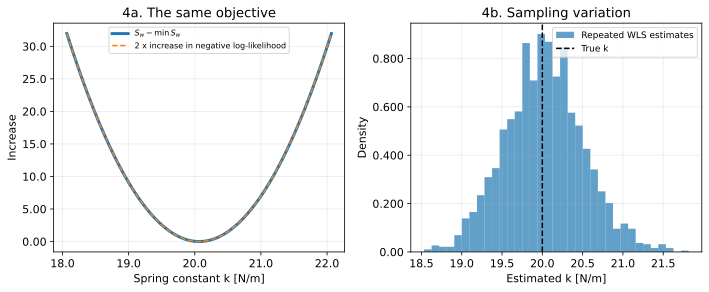

In [5]:
k_scan = np.linspace(b_wls[1] - 2, b_wls[1] + 2, 201)
residual_scan = force[:, None] - (b_wls[0] + x[:, None] * k_scan)
weighted_scan = np.sum((residual_scan / sigma[:, None]) ** 2, axis=0)
nll = np.sum(np.log(np.sqrt(2 * np.pi) * sigma)) + weighted_scan / 2
delta_weighted = weighted_scan - weighted_scan.min()
delta_nll = 2 * (nll - nll.min())
assert np.allclose(delta_weighted, delta_nll)

# 各列を独立した実験とし、2000組の係数をまとめて推定する。
rng_repeat = np.random.default_rng(102)
repeats = 2000
force_repeated = X @ b_true[:, None] + rng_repeat.normal(
    0, sigma[:, None], size=(x.size, repeats)
)
b_repeated = np.linalg.lstsq(X_white, force_repeated / sigma[:, None], rcond=None)[0]
pprint({
    "kの平均 [N/m]": sig3(b_repeated[1].mean()),
    "kの標準偏差 [N/m]": sig3(b_repeated[1].std(ddof=1)),
})

fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.20))
axes[0].plot(k_scan, delta_weighted, linewidth=3, label=r"$S_w-\min S_w$")
axes[0].plot(k_scan, delta_nll, "--", label="2 x increase in negative log-likelihood")
axes[0].set(xlabel="Spring constant k [N/m]", ylabel="Increase", title="4a. The same objective")
axes[0].legend(fontsize=8)
axes[1].hist(b_repeated[1], bins=35, density=True, alpha=0.700, label="Repeated WLS estimates")
axes[1].axvline(b_true[1], color="black", linestyle="--", label="True k")
axes[1].set(xlabel="Estimated k [N/m]", ylabel="Density", title="4b. Sampling variation")
axes[1].legend(fontsize=9)
save_figure(fig, "04_likelihood_sampling.svg")

## 4. 機械学習：未知のデータへの予測

回帰では$S/n$を平均二乗誤差（MSE）として使う。定数$n$で割っても最小化する係数は変わらない。ここでは$y=\sin(\pi x)+\varepsilon$を12次多項式$\sum_{j=0}^{12}b_jx^j$で近似する。$x$には非線形でも、係数には線形なので最小二乗法を使える。

学習誤差だけを下げると雑音まで拾うことがある。[Ridge回帰](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification)は係数の二乗に罰則を加える。$\mathbf{D}=\operatorname{diag}(0,1,\ldots,1)$とし、切片には罰則を付けない。

$$
\begin{aligned}
J(\mathbf{b})&=\frac1n\|\mathbf{y}-\mathbf{X}\mathbf{b}\|_2^2
+\lambda\|\mathbf{D}\mathbf{b}\|_2^2,\\
\nabla_{\mathbf{b}}J&=\frac2n(\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{b}
-\mathbf{X}^{\mathsf T}\mathbf{y})+2\lambda\mathbf{D}^{\mathsf T}\mathbf{D}\mathbf{b}=\mathbf{0},\\
(\mathbf{X}^{\mathsf T}\mathbf{X}+n\lambda\mathbf{D}^{\mathsf T}\mathbf{D})\hat{\mathbf{b}}
&=\mathbf{X}^{\mathsf T}\mathbf{y}.
\end{aligned}
$$

実装は$\mathbf{X}$に$\sqrt{n\lambda}\mathbf{D}$を、$\mathbf{y}$にゼロを縦に追加する。その二乗和は$S+n\lambda\|\mathbf{D}\mathbf{b}\|_2^2=nJ$となる。

学習用18点で係数を求め、独立した検証用100点で$\lambda$を選ぶ。最後に、選択に使わないテスト用1000点で評価する。入力範囲はすべて$[-1,1]$、雑音の標準偏差は$0.200$である。

<IPython.core.display.Latex object>

[{'モデル': 'OLS', '学習MSE': '0.0127', '検証MSE': '0.0641', 'テストMSE': '0.0764'},
 {'モデル': 'Ridge', '学習MSE': '0.0181', '検証MSE': '0.0328', 'テストMSE': '0.0432'}]


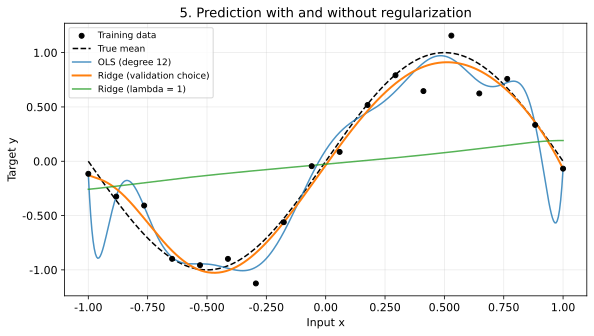

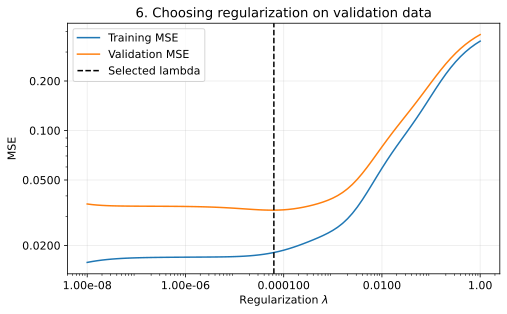

In [6]:
rng_ml = np.random.default_rng(2026)
x_train = np.linspace(-1, 1, 18)
x_valid = rng_ml.uniform(-1, 1, 100)
x_test = rng_ml.uniform(-1, 1, 1000)


def target(values):
    return np.sin(np.pi * values)


y_train = target(x_train) + rng_ml.normal(0, 0.200, x_train.size)
y_valid = target(x_valid) + rng_ml.normal(0, 0.200, x_valid.size)
y_test = target(x_test) + rng_ml.normal(0, 0.200, x_test.size)
degree = 12


def design(values):
    # 列は 1, x, x**2, ..., x**12 の順である。
    return np.vander(values, N=degree + 1, increasing=True)


X_train, X_valid, X_test = (design(values) for values in (x_train, x_valid, x_test))
penalty = np.diag([0] + [1] * degree)


def fit_ridge(lam):
    # nを掛け、本文の「平均」二乗誤差の定義と罰則の強さを一致させる。
    augmented_X = np.vstack((X_train, np.sqrt(x_train.size * lam) * penalty))
    augmented_y = np.concatenate((y_train, np.zeros(degree + 1)))
    return np.linalg.lstsq(augmented_X, augmented_y, rcond=None)[0]


lambdas = np.logspace(-8, 0, 81)
coefficients = np.array([fit_ridge(lam) for lam in lambdas])
train_mse = np.mean((X_train @ coefficients.T - y_train[:, None]) ** 2, axis=0)
valid_mse = np.mean((X_valid @ coefficients.T - y_valid[:, None]) ** 2, axis=0)
best_index = np.argmin(valid_mse)  # テストデータは選択に使わない。
best_lambda = lambdas[best_index]
b_best = coefficients[best_index]
b_unregularized = fit_ridge(0)

show_formula(rf"\lambda_\ast={tex3(best_lambda)}")
rows = []
for name, coefficient in (("OLS", b_unregularized), ("Ridge", b_best)):
    rows.append({
        "モデル": name,
        "学習MSE": sig3(np.mean((X_train @ coefficient - y_train) ** 2)),
        "検証MSE": sig3(np.mean((X_valid @ coefficient - y_valid) ** 2)),
        "テストMSE": sig3(np.mean((X_test @ coefficient - y_test) ** 2)),
    })
pprint(rows, sort_dicts=False)

x_plot = np.linspace(-1, 1, 401)
X_plot = design(x_plot)
fig, ax = plt.subplots(figsize=(8.40, 4.80))
ax.scatter(x_train, y_train, color="black", s=25, label="Training data", zorder=4)
ax.plot(x_plot, target(x_plot), "--", color="black", label="True mean")
ax.plot(x_plot, X_plot @ b_unregularized, label="OLS (degree 12)", alpha=0.800)
ax.plot(x_plot, X_plot @ b_best, label="Ridge (validation choice)", linewidth=2)
ax.plot(x_plot, X_plot @ fit_ridge(1), label="Ridge (lambda = 1)", alpha=0.800)
ax.set(xlabel="Input x", ylabel="Target y", title="5. Prediction with and without regularization")
ax.legend(fontsize=9)
save_figure(fig, "05_prediction_curves.svg")

fig, ax = plt.subplots(figsize=(7.20, 4.50))
ax.loglog(lambdas, train_mse, label="Training MSE")
ax.loglog(lambdas, valid_mse, label="Validation MSE")
ax.axvline(best_lambda, color="black", linestyle="--", label="Selected lambda")
ax.set(xlabel=r"Regularization $\lambda$", ylabel="MSE", title="6. Choosing regularization on validation data")
ax.legend()
save_figure(fig, "06_validation_curve.svg")

この例のテストMSEは、通常の最小二乗で$0.0764$、Ridgeで$0.0432$となる。正則化を強くしすぎると、図5のように曲線を十分に表せない。図6では学習誤差と検証誤差の最小値が異なる。結果は標本や特徴量の尺度にも依存するため、正則化が必ず改善するとは限らない。

## 結論

この記事では、最小二乗法を物理の定数推定、統計の最尤推定、機械学習の回帰という三つの用途から確認した。

共通する計算は残差の二乗和の最小化である。物理では法則と測定精度、統計では誤差分布と推定のばらつき、機械学習では未知のデータに対する誤差を確認する。同じ解法を使っても、結果を判断するための条件は用途によって異なる。